# Hamiltonian Monte Carlo

**Gabriel Trabelsi**

Implementations of a leapfrog integrator, a Hamiltonian Monte Carlo (HMC) sampler and a two-dimensional MALA sampler, compared with random-walk Metropolis on a Gaussian target and on a two-component Gaussian mixture.

**Academic context:** supplied TP6 practical (Metropolis-Hastings, MALA, HMC), Statistique Computationnelle, Sorbonne Université, Master 1, 2025-2026. The supplied header gives no individual instructor attribution. Function signatures and docstrings come from the exercise framework; the implementations and experiments are by Gabriel Trabelsi.

**About the outputs:** in the original notebook, some figures were produced before the final version of the integrator cell was run, so its saved outputs did not all match the code. The selected cells were therefore re-executed unchanged, in order, in a fresh kernel on 15 October 2026, with the fixed seed added below. Progress bars and object addresses are removed. The Euler-integrator and parameter-tuning questions of the practical were not completed and are not included.

In [ ]:
"""""""""""""""""
Required packages
"""""""""""""""""
import seaborn as sns
import autograd.numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
# package which differentiates standard Python and Numpy code
from autograd import grad
# to get progress bars
from tqdm import tqdm

In [ ]:
np.random.seed(0)  # Added for this presentation run; the original notebook used no fixed seed.

## 1. Target densities

`multi_gauss` and `mixture` return the potential $V=-\log\pi$ of a Gaussian density and of a mixture of densities. Gradients of $V$ are obtained with `autograd`.

In [ ]:
def multi_gauss(mu, sigma):
    """
    Inputs
    ----------
    mu: mean of the Gaussian distribution
    sigma: covariance matrix of the Gaussian distribution
    
    Outputs
    -------
    logp: opposite of the loglikelihood
    """

    def logp(x):
        n = mu.size
        diff = (x - mu)
        logdet = np.linalg.slogdet(sigma)[1]
        inv_sigma = np.linalg.inv(sigma)

        return n/2*np.log(2*np.pi) + 1/2 * logdet  + 1/2*(diff.T)@inv_sigma@diff
        
    
    return logp

def mixture(log_prob, weights):
    """
    Inputs
    ----------
    log_prob: opposite of the likelihood of each term
    weights: weights of the components of the mixture
    
    Outputs
    -------
    logp: opposite of the loglikelihood of the mixture
    """
    
    def logp(x):
        logprobvalue = np.array([lp(x) for lp in log_prob])
        return -np.log(np.sum(weights * np.exp(-logprobvalue)))
        

    return logp

## 2. Random-walk Metropolis (baseline)

Gaussian proposal $Z = X_k + \sigma\varepsilon$, accepted with probability $\min\big(1, e^{V(X_k)-V(Z)}\big)$. It serves as the point of comparison below.

In [ ]:
def HM_monte_carlo(n_samples, log_prob, initial_state, step_size = 0.1):
    """
    Inputs
    ----------
    n_samples: number of samples to return
    log_prob: opposite of the loglikelihood to sample from
    initial_state: initial sample
    step_size: standard deviation of the proposed moves
    
    Outputs
    -------
    samples: samples from the MCMC algorithm
    accepted: array of 0 and 1 to display which proposed moves have been accepted
    """
    initial_state = np.array(initial_state)
    
    samples  = [initial_state]
    accepted = []

    size = (n_samples,) + initial_state.shape[:1]
    
    # random variable to sample proposed moves
    epsilon = st.norm(0, 1).rvs(size)
    

    for noise in tqdm(epsilon):
        unif = st.uniform().rvs()
        Z = initial_state + step_size*noise
        if unif < min(1, np.exp(-log_prob(Z) + log_prob(initial_state))):
            accepted.append(1); samples.append(Z)
            initial_state = Z
        else:
            samples.append(initial_state); accepted.append(0)
        
    

        

    return (np.array(samples[1:]),np.array(accepted),)

## 3. MALA

Langevin proposal $Z = X_k - \frac{\sigma^2}{2}\nabla V(X_k) + \sigma\varepsilon$. The proposal is not symmetric, so the acceptance ratio includes the forward and reverse Gaussian proposal densities; it is computed on the log scale.

In [ ]:
def MALA_monte_carlo(n_samples, log_prob, initial_state, step_size = 0.1):
    initial_state = np.array(initial_state)

    gradV = grad(log_prob)

    samples  = [initial_state]
    accepted = []

    size = (n_samples,) + initial_state.shape[:1]
    
    epsilon = st.norm(0, 1).rvs(size)
    
    for noise in tqdm(epsilon):
        Z = initial_state - (step_size**2)/2 * gradV(initial_state) + step_size * noise
        log_RejetQ = st.norm.logpdf(initial_state, loc=Z - step_size**2/2 * gradV(Z), scale=step_size).sum() \
                   - st.norm.logpdf(Z, loc=initial_state - step_size**2/2 * gradV(initial_state), scale=step_size).sum()
        if np.log(st.uniform().rvs()) < min(0, -log_prob(Z) + log_prob(initial_state) + log_RejetQ):
            accepted.append(1)
            samples.append(Z)
            initial_state = Z
        else:
            samples.append(initial_state)
            accepted.append(0)

    return (np.array(samples[1:]), np.array(accepted),)


## 4. Leapfrog integrator

With $H(q,p)=V(q)+\tfrac12\|p\|^2$, each step makes a half step on the momentum, a full step on the position and a second half step on the momentum:

$$p_{1/2}=p-\tfrac{\varepsilon}{2}\nabla V(q),\qquad q'=q+\varepsilon\,p_{1/2},\qquad p'=p_{1/2}-\tfrac{\varepsilon}{2}\nabla V(q').$$

The scheme is symplectic and time-reversible. The final momentum is negated so that the proposal is an involution.

In [ ]:
def leapfrog_integrator(q, p, gradientV, T, step):
    """
    Inputs
    ----------
    q: initial position
    p: initial momentum
    gradientV: gradient of the velocity
    T: time horizon
    step: step size to discretize the ODE
    
    Outputs
    -------
    q, p: last position and last momentum
    posisions: sequence of positions produced by the leapfrog integrator
    momentums: sequence of momentums produced by the leapfrog integrator
    """
    
    q, p      = np.copy(q), np.copy(p)
    pos, moms = [np.copy(q)], [np.copy(p)]

    vq = gradientV(q)
    nb_steps = int(T / step)
    
    for it in range(nb_steps):
        p_inter = p - step/2 * vq
        q = q + step * p_inter
        vq = gradientV(q)
        p = p_inter - step/2 * vq

        pos.append(q)
        moms.append(p)

    return q, -p, np.array(pos), np.array(moms)

### Leapfrog trajectories

One trajectory and then ten trajectories with random initial momenta for a standard two-dimensional Gaussian ($T=1$, $\varepsilon=0.1$), followed by ten trajectories for an equal-weight mixture of $\mathcal N((2,2),I_2)$ and $\mathcal N((-2,-2),I_2)$ ($T=2$).

[[0.         0.        ]
 [0.17640523 0.04001572]
 [0.35104642 0.07963128]
 [0.52217713 0.11845054]
 [0.68808608 0.15608528]
 [0.84711417 0.19215917]
 [0.99767111 0.22631147]
 [1.13825134 0.25820066]
 [1.26744906 0.28750784]
 [1.38397229 0.31393994]
 [1.4866558  0.33723264]]


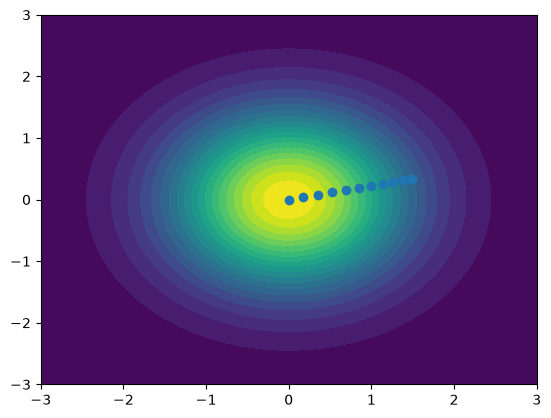

In [ ]:
log_density = multi_gauss(np.zeros(2), np.eye(2))
gradV = grad(log_density)

pos = st.norm(loc = 0, scale = 1).rvs(size=2)
pos = leapfrog_integrator(q=np.zeros(2), p=pos, gradientV=gradV, T=1, step=0.1)[2]

x = np.linspace(-3, 3, 200)
y = np.linspace(-3, 3, 200)

X, Y = np.meshgrid(x,y) # X[i,j] nous donne le point d'abcisse i,j
densite = lambda x: np.exp(-log_density(x))
Z = np.array([[densite([X[i,j], Y[i,j]]) for j in range(len(x))] for i in range(len(y))])

plt.contourf(X, Y, Z, levels=20)
print(pos)
plt.scatter(pos[:, 0], pos[:, 1])

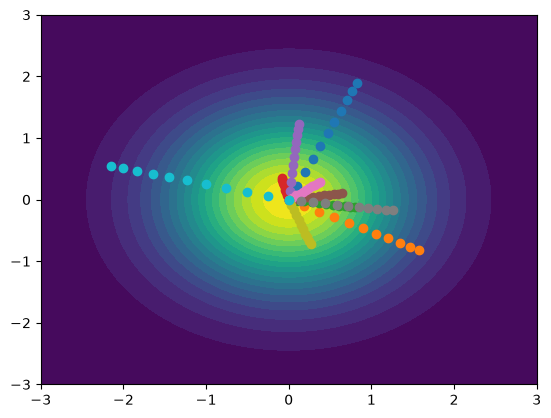

In [ ]:
n = 10
plt.contourf(X, Y, Z, levels=20)
positions = [st.norm(loc = 0, scale = 1).rvs(size=2) for i in range(n)]
leapfrog = [leapfrog_integrator(q=np.zeros(2), p=pos, gradientV=gradV, T=1, step=0.1)[2] for pos in positions]

for k in range(len(leapfrog)):
    plt.scatter(leapfrog[k][:,0], leapfrog[k][:,1])

**Observation.** Starting from the mode, the distance between consecutive points shrinks as the trajectory moves outwards: kinetic energy is converted into potential energy. For a standard Gaussian the exact flow is $q(t)=q_0\cos t+p_0\sin t$, so from $q_0=0$ the end point at $T=1$ should be $\sin(1)\,p_0$. In the printed run, $p_0\approx(1.764,\,0.400)$ gives $\sin(1)\,p_0\approx(1.484,\,0.337)$, while the leapfrog end point is $(1.487,\,0.337)$: with $\varepsilon=0.1$ the discretisation error is of order $10^{-3}$. With random momenta, the ten trajectories leave the mode in all directions, with lengths proportional to $\|p_0\|$.

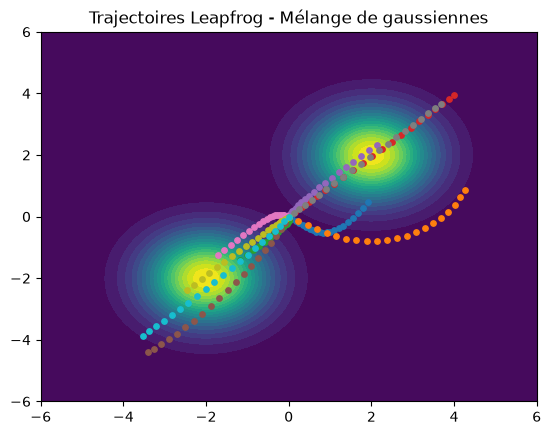

In [ ]:
# Définition du mélange de gaussiennes
mu1 = np.array([2.0, 2.0])
mu2 = np.array([-2.0, -2.0])
sigma1 = np.eye(2)
sigma2 = np.eye(2)

log_prob1 = multi_gauss(mu1, sigma1)
log_prob2 = multi_gauss(mu2, sigma2)
log_density_mix = mixture([log_prob1, log_prob2], [0.5, 0.5])
gradV_mix = grad(log_density_mix)

# Grille pour le contourf
x = np.linspace(-6, 6, 200)
y = np.linspace(-6, 6, 200)
X, Y = np.meshgrid(x, y)
Z = np.array([[np.exp(-log_density_mix(np.array([X[i,j], Y[i,j]]))) for j in range(len(x))] for i in range(len(y))])

# Plusieurs trajectoires leapfrog
n = 10
plt.contourf(X, Y, Z, levels=20)
colors = plt.cm.tab10(np.linspace(0, 1, n))

for k in range(n):
    p0 = st.norm(0, 1).rvs(size=2)
    positions = leapfrog_integrator(q=np.zeros(2), p=p0, gradientV=gradV_mix, T=2, step=0.1)[2]
    plt.scatter(positions[:, 0], positions[:, 1], color=colors[k], s=15)

plt.title("Trajectoires Leapfrog - Mélange de gaussiennes")
plt.show()


**Observation.** The trajectories start at the origin, the saddle point between the two modes, where $\nabla V=0$ by symmetry. Depending on its initial momentum, each one falls towards one of the modes, passes through it and climbs on the far side before slowing down. The moves follow the geometry of the target rather than a random walk, which is what allows HMC to make long proposals that are still accepted.

## 5. HMC loop

At each iteration, a momentum $p_0\sim\mathcal N(0,I)$ is drawn, the leapfrog integrator is run for a time $T$ with step $\varepsilon$, and the end point $(q',p')$ is accepted with probability $\min\big(1, e^{H(q,p_0)-H(q',p')}\big)$. The trajectory length is fixed and the mass matrix is the identity.

In [ ]:
def hamiltonian_monte_carlo(n_samples, log_prob, initial_position, T = 1, step_size = 0.1):
    """
    Inputs
    ----------
    n_samples: number of samples to return.
    log_prob: opposite of the target log probability.
    initial_position: a place to start sampling from.
    T: length of leapfrog integration.
    step_size: step size of the integration scheme.
    
    Outputs
    -------
    samples: samples produced by the HMC.
    sample_positions: positions obtained by the leapfrog integrator at each time step.
    sample_momentums: momentums obtained by the leapfrog integrator at each time step.
    accepted: array of 0 and 1 to display which proposed moves have been accepted.
    """
    initial_position = np.array(initial_position)
    
    gradV = grad(log_prob)

    samples = [initial_position]
    sample_positions, sample_momentums = [], []
    accepted = []

    size = (n_samples,) + initial_position.shape[:1]
    
    # all momentums
    momentum = st.norm(0, 1).rvs(size)
    for p0 in tqdm(momentum):
        q_current = samples[-1]
        p_current = p0

        q_current, p_current, positions, momentums = leapfrog_integrator(q=q_current, p=p_current, gradientV=gradV, T=T, step=step_size)
        hamilton = log_prob(q_current)+1/2*(p_current**2).sum()-log_prob(samples[-1])-1/2*(p0**2).sum()

        alpha = min(np.exp(-hamilton), 1)
        
        if st.uniform.rvs()<alpha:
            accepted.append(1)
            samples.append(q_current)
        else:
            accepted.append(0)
            samples.append(samples[-1])

        sample_positions.append(positions); sample_momentums.append(momentums)

        



    return (np.array(samples[1:]),np.array(sample_positions),np.array(sample_momentums),np.array(accepted),)

## 6. Gaussian target

Chains of 500 iterations started at the origin: effect of the integration time $T$, then of the step size $\varepsilon$, then comparison with random-walk Metropolis (step 0.5) on scatter and trace plots. Acceptance rates are shown in the panel titles.

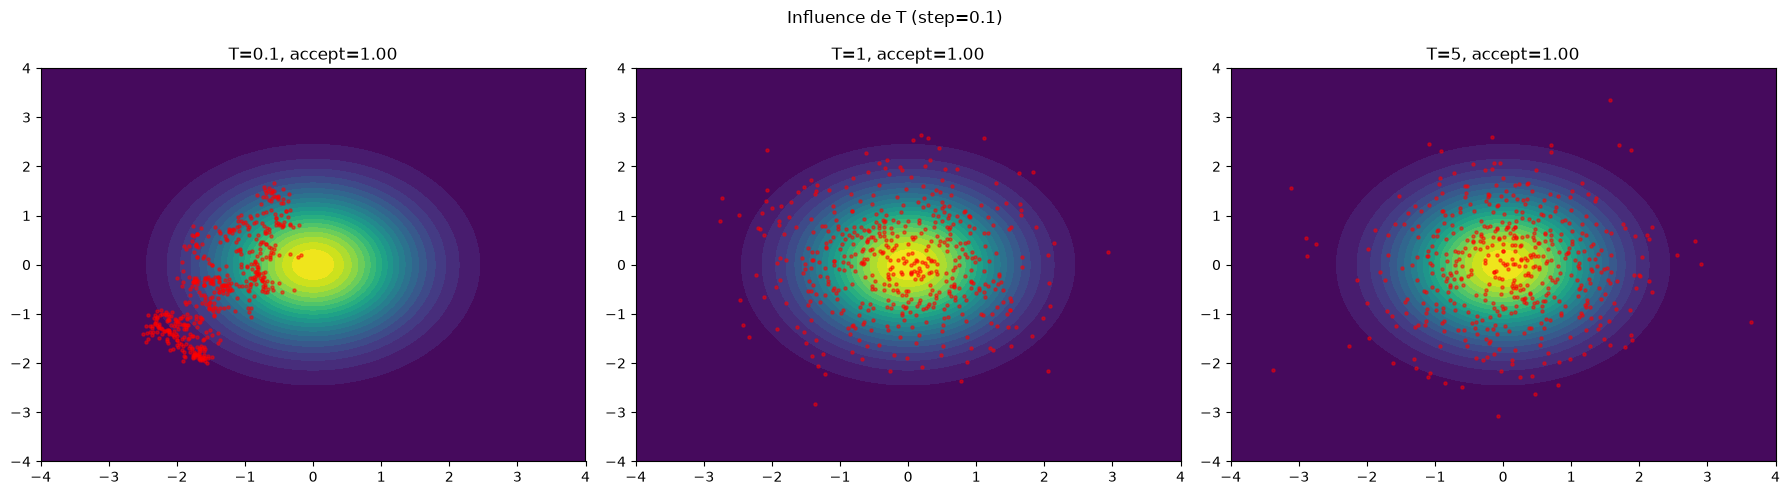

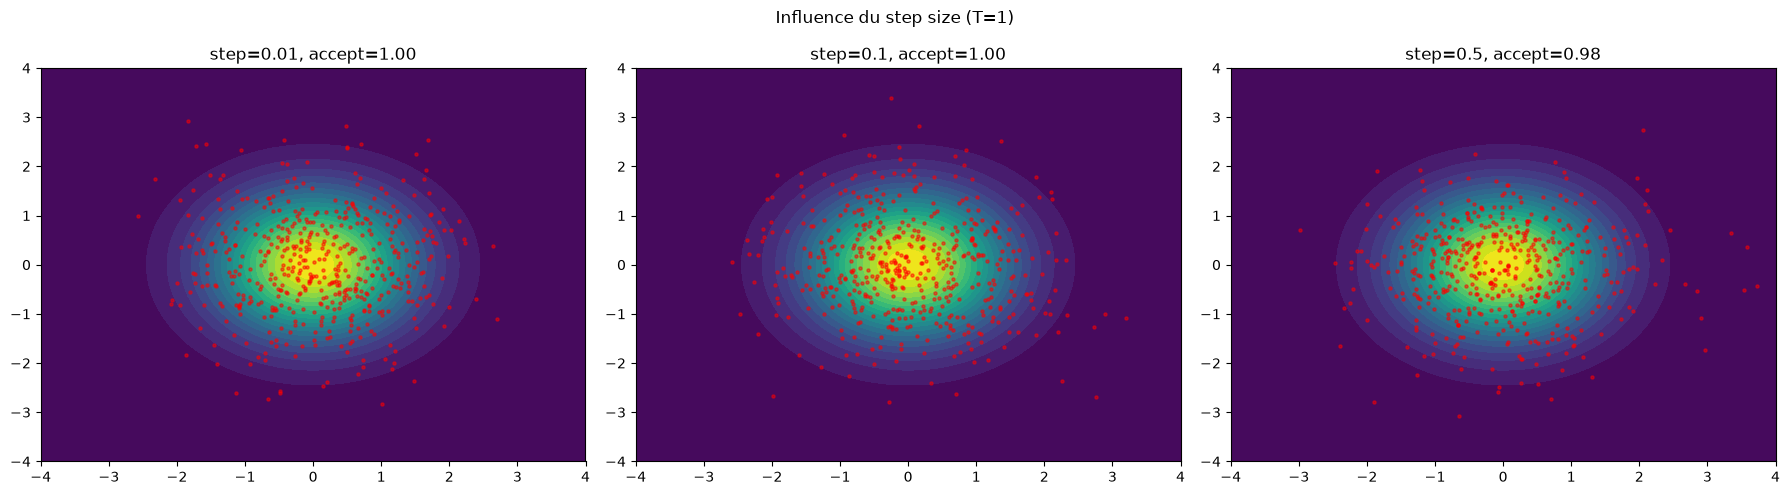

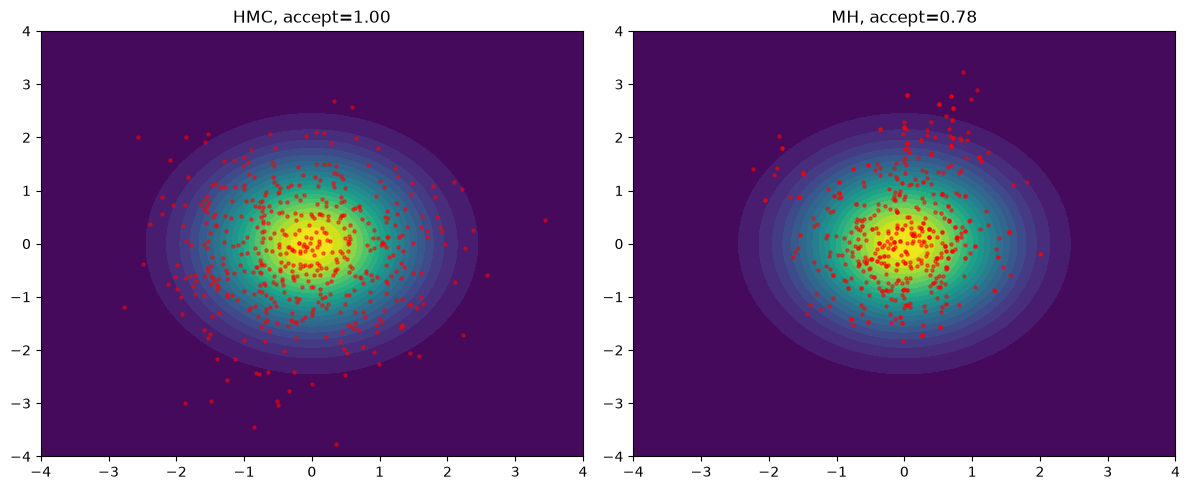

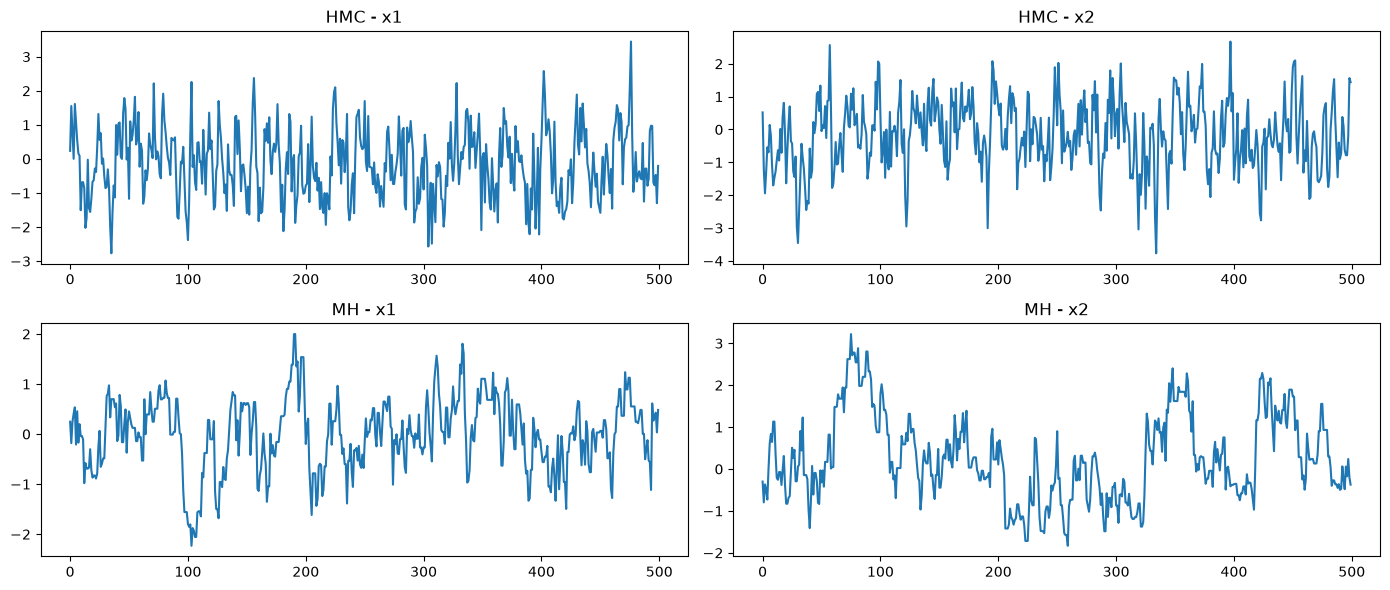

In [ ]:
# Cible : gaussienne 2D
log_density = multi_gauss(np.zeros(2), np.eye(2))
gradV = grad(log_density)

x = np.linspace(-4, 4, 100)
y = np.linspace(-4, 4, 100)
X, Y = np.meshgrid(x, y)
Z = np.array([[np.exp(-log_density(np.array([X[i,j], Y[i,j]]))) for j in range(len(x))] for i in range(len(y))])

n_samples = 500
q0 = np.zeros(2)

# ============================================
# i) Influence de T
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, T in enumerate([0.1, 1, 5]):
    samples, pos, moms, acc = hamiltonian_monte_carlo(n_samples, log_density, q0, T=T, step_size=0.1)
    axes[idx].contourf(X, Y, Z, levels=20)
    axes[idx].scatter(samples[:, 0], samples[:, 1], s=5, c='red', alpha=0.5)
    axes[idx].set_title(f"T={T}, accept={acc.mean():.2f}")
plt.suptitle("Influence de T (step=0.1)")
plt.tight_layout()
plt.show()

# ============================================
# ii) Influence du step size
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, step in enumerate([0.01, 0.1, 0.5]):
    samples, pos, moms, acc = hamiltonian_monte_carlo(n_samples, log_density, q0, T=1, step_size=step)
    axes[idx].contourf(X, Y, Z, levels=20)
    axes[idx].scatter(samples[:, 0], samples[:, 1], s=5, c='red', alpha=0.5)
    axes[idx].set_title(f"step={step}, accept={acc.mean():.2f}")
plt.suptitle("Influence du step size (T=1)")
plt.tight_layout()
plt.show()

# ============================================
# iii) Comparaison avec MH
# ============================================
samples_hmc, _, _, acc_hmc = hamiltonian_monte_carlo(n_samples, log_density, q0, T=1, step_size=0.1)
samples_mh, acc_mh = HM_monte_carlo(n_samples, log_density, q0, step_size=0.5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].contourf(X, Y, Z, levels=20)
axes[0].scatter(samples_hmc[:, 0], samples_hmc[:, 1], s=5, c='red', alpha=0.5)
axes[0].set_title(f"HMC, accept={acc_hmc.mean():.2f}")

axes[1].contourf(X, Y, Z, levels=20)
axes[1].scatter(samples_mh[:, 0], samples_mh[:, 1], s=5, c='red', alpha=0.5)
axes[1].set_title(f"MH, accept={acc_mh.mean():.2f}")
plt.tight_layout()
plt.show()

# Trace plots
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
axes[0, 0].plot(samples_hmc[:, 0]); axes[0, 0].set_title("HMC - x1")
axes[0, 1].plot(samples_hmc[:, 1]); axes[0, 1].set_title("HMC - x2")
axes[1, 0].plot(samples_mh[:, 0]); axes[1, 0].set_title("MH - x1")
axes[1, 1].plot(samples_mh[:, 1]); axes[1, 1].set_title("MH - x2")
plt.tight_layout()
plt.show()

**Observations.**

- *Integration time.* With $T=0.1$ (a single leapfrog step), each move is tiny: after 500 iterations the chain has drifted away from the centre and covers only part of the target. With $T=1$ and $T=5$ the samples cover the target. The acceptance rate is 1.00 in all three runs, so here it says nothing about exploration.
- *Step size.* All three runs cover the target. Acceptance only drops to 0.98 at $\varepsilon=0.5$, as the energy error of the leapfrog scheme grows with the step. Since $T$ is fixed, $\varepsilon=0.01$ costs 100 gradient evaluations per iteration, against 10 for $\varepsilon=0.1$, for a similar picture.
- *Comparison.* Random-walk Metropolis with step 0.5 accepts 78% of its moves, and its trace plots show slow excursions lasting tens of iterations (for instance, $x_2$ stays near 2 between iterations 60 and 100). The HMC traces look much closer to independent draws. The price is about ten gradient evaluations per HMC iteration, against one density evaluation for Metropolis.

## 7. Gaussian mixture

The same experiments on the two-component mixture, where moving between the modes is the main difficulty, followed by a comparison of HMC, random-walk Metropolis and MALA.

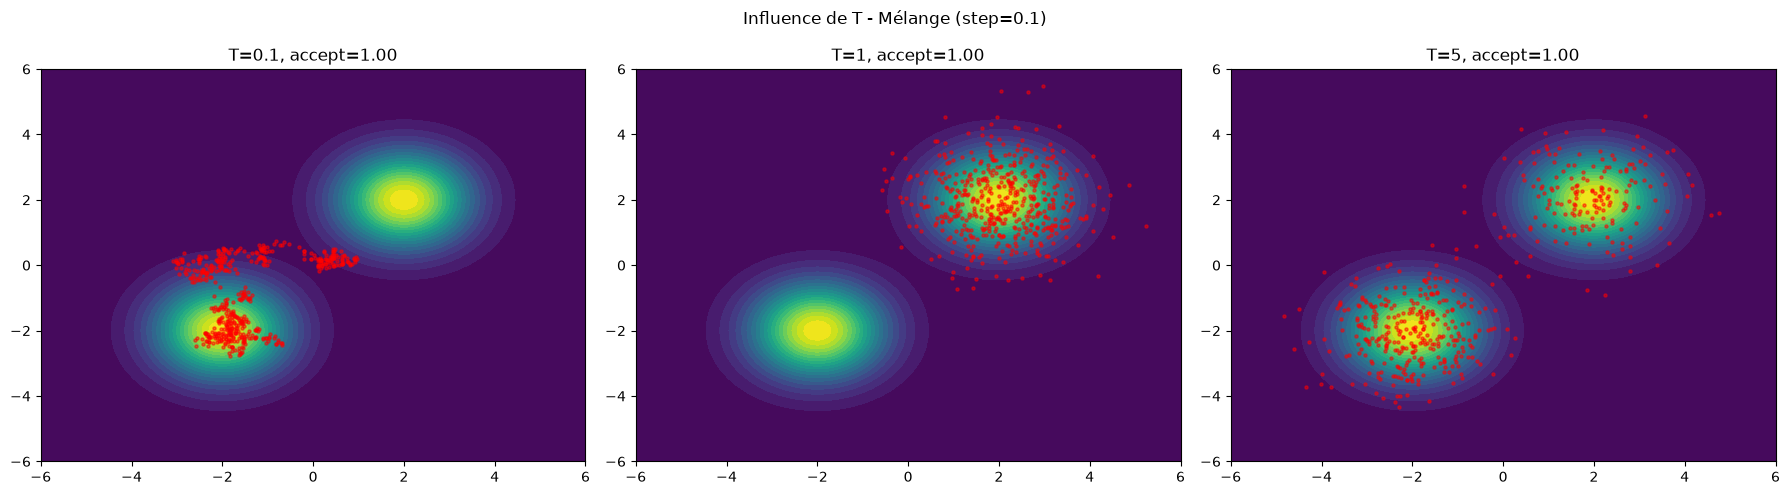

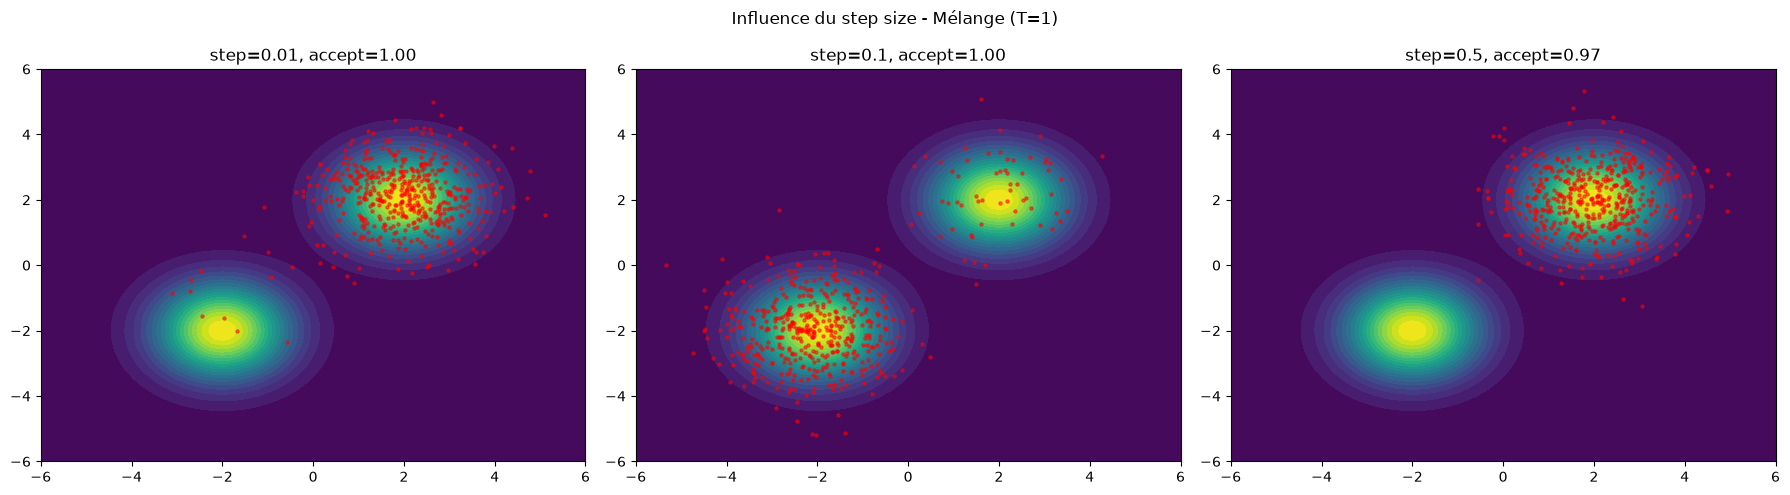

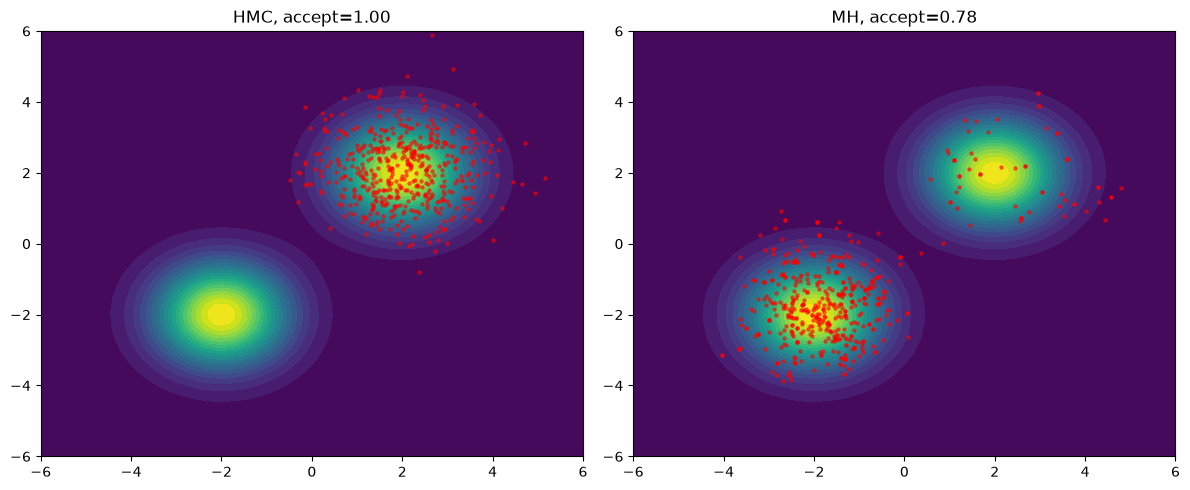

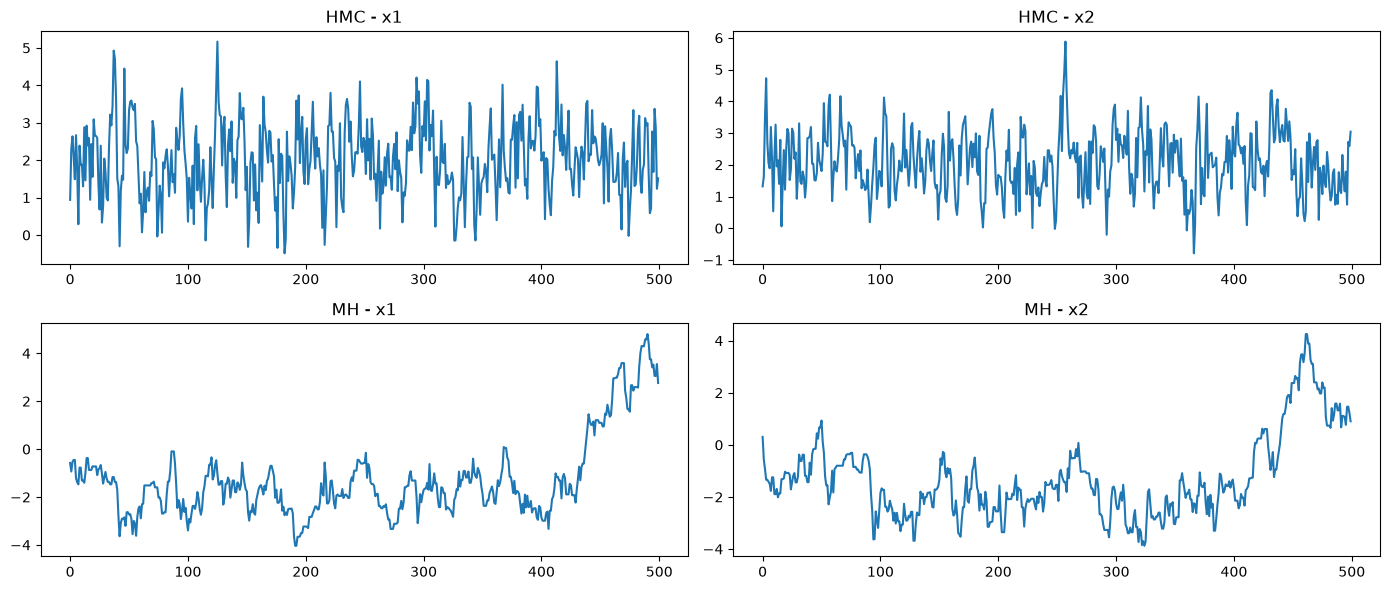

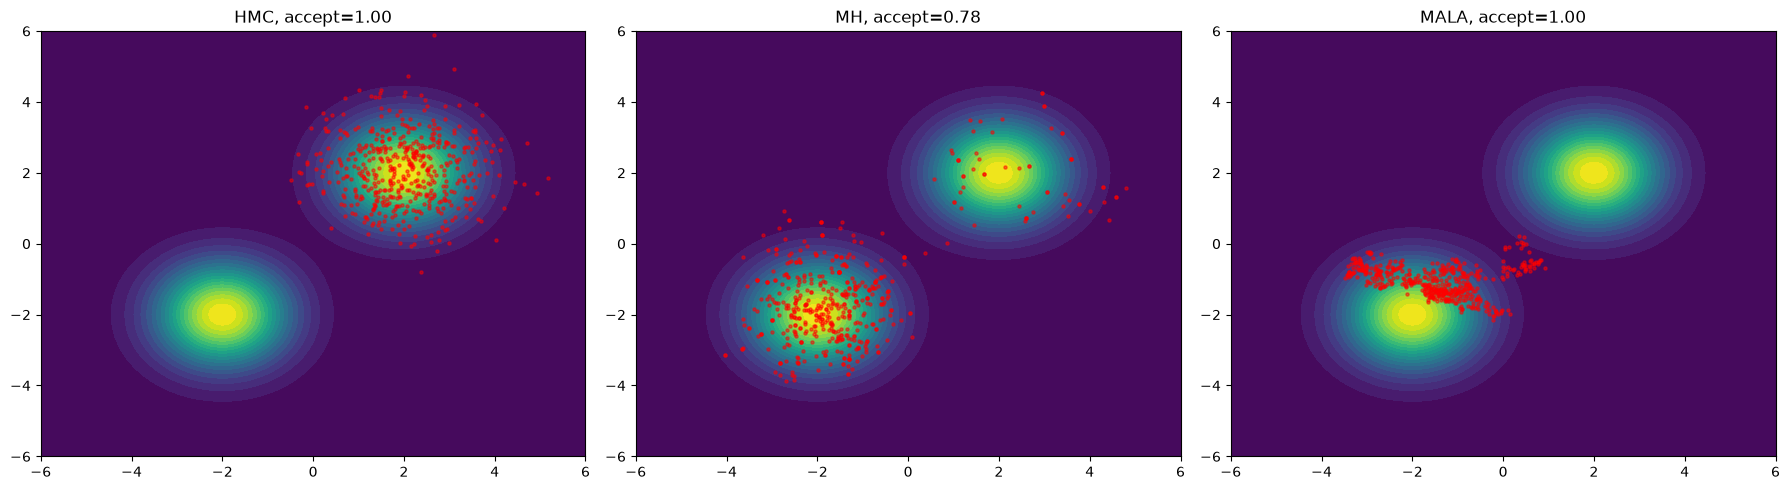

In [ ]:
# Cible : mélange de gaussiennes 2D
mu1 = np.array([2.0, 2.0])
mu2 = np.array([-2.0, -2.0])
log_prob1 = multi_gauss(mu1, np.eye(2))
log_prob2 = multi_gauss(mu2, np.eye(2))
log_density_mix = mixture([log_prob1, log_prob2], [0.5, 0.5])

x = np.linspace(-6, 6, 100)
y = np.linspace(-6, 6, 100)
X, Y = np.meshgrid(x, y)
Z = np.array([[np.exp(-log_density_mix(np.array([X[i,j], Y[i,j]]))) for j in range(len(x))] for i in range(len(y))])

n_samples = 500
q0 = np.zeros(2)

# ============================================
# i) Influence de T
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, T in enumerate([0.1, 1, 5]):
    samples, pos, moms, acc = hamiltonian_monte_carlo(n_samples, log_density_mix, q0, T=T, step_size=0.1)
    axes[idx].contourf(X, Y, Z, levels=20)
    axes[idx].scatter(samples[:, 0], samples[:, 1], s=5, c='red', alpha=0.5)
    axes[idx].set_title(f"T={T}, accept={acc.mean():.2f}")
plt.suptitle("Influence de T - Mélange (step=0.1)")
plt.tight_layout()
plt.show()

# ============================================
# ii) Influence du step size
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, step in enumerate([0.01, 0.1, 0.5]):
    samples, pos, moms, acc = hamiltonian_monte_carlo(n_samples, log_density_mix, q0, T=1, step_size=step)
    axes[idx].contourf(X, Y, Z, levels=20)
    axes[idx].scatter(samples[:, 0], samples[:, 1], s=5, c='red', alpha=0.5)
    axes[idx].set_title(f"step={step}, accept={acc.mean():.2f}")
plt.suptitle("Influence du step size - Mélange (T=1)")
plt.tight_layout()
plt.show()

# ============================================
# iii) Comparaison avec MH
# ============================================
samples_hmc, _, _, acc_hmc = hamiltonian_monte_carlo(n_samples, log_density_mix, q0, T=1, step_size=0.1)
samples_mh, acc_mh = HM_monte_carlo(n_samples, log_density_mix, q0, step_size=0.5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].contourf(X, Y, Z, levels=20)
axes[0].scatter(samples_hmc[:, 0], samples_hmc[:, 1], s=5, c='red', alpha=0.5)
axes[0].set_title(f"HMC, accept={acc_hmc.mean():.2f}")

axes[1].contourf(X, Y, Z, levels=20)
axes[1].scatter(samples_mh[:, 0], samples_mh[:, 1], s=5, c='red', alpha=0.5)
axes[1].set_title(f"MH, accept={acc_mh.mean():.2f}")
plt.tight_layout()
plt.show()

# Trace plots
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
axes[0, 0].plot(samples_hmc[:, 0]); axes[0, 0].set_title("HMC - x1")
axes[0, 1].plot(samples_hmc[:, 1]); axes[0, 1].set_title("HMC - x2")
axes[1, 0].plot(samples_mh[:, 0]); axes[1, 0].set_title("MH - x1")
axes[1, 1].plot(samples_mh[:, 1]); axes[1, 1].set_title("MH - x2")
plt.tight_layout()
plt.show()

# ============================================
# iv) Comparaison avec MALA
# ============================================
samples_mala, acc_mala = MALA_monte_carlo(n_samples, log_density_mix, q0, step_size=0.1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].contourf(X, Y, Z, levels=20)
axes[0].scatter(samples_hmc[:, 0], samples_hmc[:, 1], s=5, c='red', alpha=0.5)
axes[0].set_title(f"HMC, accept={acc_hmc.mean():.2f}")

axes[1].contourf(X, Y, Z, levels=20)
axes[1].scatter(samples_mh[:, 0], samples_mh[:, 1], s=5, c='red', alpha=0.5)
axes[1].set_title(f"MH, accept={acc_mh.mean():.2f}")

axes[2].contourf(X, Y, Z, levels=20)
axes[2].scatter(samples_mala[:, 0], samples_mala[:, 1], s=5, c='red', alpha=0.5)
axes[2].set_title(f"MALA, accept={acc_mala.mean():.2f}")
plt.tight_layout()
plt.show()


**Observations.**

- *Integration time.* With $T=0.1$ the chain stays around the lower mode and in the region between the modes; with $T=1$ it stays in the upper mode; only $T=5$ visits both. Crossing requires both energy and time. The potential at the saddle point is about $4-\log 2\approx3.3$ above its value at a mode, and in two dimensions the kinetic energy $\tfrac12\|p_0\|^2$ of a standard Gaussian momentum is exponential with mean 1, so it exceeds this barrier with probability $e^{-3.3}\approx4\%$. The trajectory must also be long enough to cover the distance $\sqrt{32}\approx5.7$ between the modes.
- *Step size.* With $T=1$, each chain spends almost all its time in one mode, with only a few visits to the other for $\varepsilon=0.01$ and $\varepsilon=0.1$; which mode is explored depends on the run. Acceptance stays between 0.97 and 1.00.
- *Comparison.* HMC with $T=1$ never leaves the upper mode. Random-walk Metropolis spends more than 400 iterations around the lower mode and only reaches the upper one at the end of the run. MALA with $\sigma=0.1$ accepts every move, but its moves are so small that the chain has only drifted from the origin towards the lower mode.
- *Conclusion.* With 500 iterations, none of these samplers recovers the two equal-weight modes reliably, and acceptance rates close to 1 are no evidence of good mixing. Longer or randomised trajectory lengths, tempering, or several chains started from dispersed points would be natural next steps; they are not implemented here.

## Limits

Each setting is a single chain of 500 iterations. The notebook reports acceptance rates, scatter plots and trace plots only: there is no effective-sample-size computation, no multi-chain convergence diagnostic and no tuning of the trajectory length or mass matrix.